# Домашняя работа: квантизация и дистилляция LLM

В этой работе вы самостоятельно проведёте эксперименты с квантизацией и дистилляцией LLM и проверите, сколько качества при этом теряет модель. Задача, на которую обучаемся, — разбор запросов к голосовому ассистенту из датасета MASSIVE (ru-RU): по запросу модель возвращает JSON с intent и slots. Подробнее: https://huggingface.co/datasets/AmazonScience/massive

### Сперва настроим окружение и подготовим код для экспериментов

In [1]:
# Раскомментируйте в новом окружении, затем перезапустите kernel:
# %pip install "torch==2.8.0" "transformers==4.55.2" "datasets==4.1.1" \
#     "accelerate==1.10.1" "llmcompressor==0.8.1" "compressed-tensors==0.12.2" \
#     "numpy==2.2.6" "pandas==2.2.3" "safetensors>=0.5" "huggingface-hub<1" tqdm

In [2]:
import gc
import json
import math
import random
import re
import shutil
import struct
from collections import Counter
from collections.abc import Sequence
from contextlib import nullcontext
from dataclasses import asdict, dataclass
from importlib.metadata import version
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import Dataset, DatasetDict, load_dataset
from IPython.display import display
from tqdm.auto import tqdm
from transformers import (
    AutoConfig, AutoModelForCausalLM, AutoTokenizer,
    CompressedTensorsConfig, GenerationConfig, PreTrainedModel, PreTrainedTokenizerBase,
    Trainer, TrainingArguments, set_seed,
)

/ephemeral/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEED = 42
ARTIFACTS = Path("artifacts_compression_hw")
ARTIFACTS.mkdir(exist_ok=True)
set_seed(SEED)

def clean_memory() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def ensure_empty_dir(path: str | Path) -> Path:
    path = Path(path)
    if path.exists() and any(path.iterdir()):
        raise FileExistsError(f"{path} уже существует и не пустой")
    path.mkdir(parents=True, exist_ok=True)
    return path

environment = {
    p: version(p) for p in (
        "torch", "transformers", "datasets", "llmcompressor",
        "compressed-tensors", "numpy", "safetensors",
    )
}
print(environment)
(ARTIFACTS / "environment.json").write_text(
    json.dumps(environment, indent=2), encoding="utf-8"
)

{'torch': '2.8.0', 'transformers': '4.55.2', 'datasets': '4.1.1', 'llmcompressor': '0.8.1', 'compressed-tensors': '0.12.2', 'numpy': '2.2.6', 'safetensors': '0.8.0'}


181

## Загрузка MASSIVE

Используем датасет MASSIVE. Все калибровочные примеры и данные для дистилляции берём только из train. Оцениваем на валидации (dev).

In [4]:
DATASET_ID = "AmazonScience/massive"
DATASET_REVISION = "ed58ac423a2f4121720918bf5301577edce4ffd3"  # refs/convert/parquet
LOCALE = "ru-RU"

dataset_url = f"hf://datasets/{DATASET_ID}@{DATASET_REVISION}/{LOCALE}"
data_files = {
    "train": f"{dataset_url}/train/0000.parquet",
    "validation": f"{dataset_url}/validation/0000.parquet",
    "test": f"{dataset_url}/test/0000.parquet",
}
raw = load_dataset("parquet", data_files=data_files)
print(raw)

DatasetDict({
    train: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments'],
        num_rows: 11514
    })
    validation: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments'],
        num_rows: 2033
    })
    test: Dataset({
        features: ['id', 'locale', 'partition', 'scenario', 'intent', 'utt', 'annot_utt', 'worker_id', 'slot_method', 'judgments'],
        num_rows: 2974
    })
})


In [5]:
example_index = 0
example_raw = raw["train"][example_index]
print("Исходная запись MASSIVE:")
print(json.dumps(
    {key: example_raw[key] for key in ("id", "utt", "annot_utt", "intent")},
    ensure_ascii=False, indent=2,
))

Исходная запись MASSIVE:
{
  "id": "1",
  "utt": "разбуди меня в девять утра в пятницу",
  "annot_utt": "разбуди меня в [time : девять утра] в [date : пятницу]",
  "intent": 48
}


### Сконвертируем данные для калибровки

В MASSIVE текст запроса лежит в поле `utt`, intent записан числом, а slots отмечены прямо в тексте поля `annot_utt`, например `[time : семь утра]`. Модель должна по запросу вернуть JSON с названием intent и списком slots в виде пар «тип — значение». Поэтому преобразуем запись в `text` — исходный запрос — и `gold` — эталонный JSON-ответ. Такой формат удобнее для калибровки и подсчёта метрик.

In [6]:
SLOT_PATTERN = re.compile(r"\[([^:\[\]]+?)\s*:\s*([^\[\]]*?)\]")

def extract_slots(annot_utt: str) -> list[list[str]]:
    """Достаёт slots из разметки MASSIVE вида `[time : семь утра]`.

    Args:
        annot_utt: размеченный запрос из поля `annot_utt`.

    Returns:
        Список пар `[тип, значение]` в порядке появления в запросе.
    """
    return [[m.group(1).strip(), m.group(2).strip()]
            for m in SLOT_PATTERN.finditer(annot_utt)]

def target_json(intent: str, slots: list[list[str]]) -> str:
    """Собирает эталонный ответ в компактный JSON.

    Args:
        intent: название intent.
        slots: список пар `[тип, значение]`.

    Returns:
        Строка `{"intent":...,"slots":[...]}` без пробелов между полями.
    """
    return json.dumps(
        {"intent": intent, "slots": slots},
        ensure_ascii=False, separators=(",", ":"),
    )

def prepare_massive(raw_splits: DatasetDict) -> DatasetDict:
    """Переводит сплиты MASSIVE в формат запрос - эталонный JSON.

    Args:
        raw_splits: исходные сплиты MASSIVE с полями `id`, `utt`, `intent`, `annot_utt`.

    Returns:
        Сплиты с полями `id`, `text` (запрос) и `gold` (эталонный JSON).
    """
    intent_feature = raw_splits["train"].features["intent"]

    def convert(row: dict[str, Any]) -> dict[str, str]:
        intent = intent_feature.int2str(row["intent"])
        slots = extract_slots(row["annot_utt"])
        return {
            "id": str(row["id"]), "text": row["utt"],
            "gold": target_json(intent, slots),
        }

    return DatasetDict({
        split: ds.map(convert, remove_columns=ds.column_names)
        for split, ds in raw_splits.items()
    })

In [ ]:

data = prepare_massive(raw)
INTENTS = list(raw["train"].features["intent"].names)
SLOT_TYPES = sorted({
    kind for row in raw["train"]
    for kind, value in extract_slots(row["annot_utt"])
})
train_data = data["train"]
DEV_SAMPLES = None
dev_data = data["validation"]
if DEV_SAMPLES is not None:
    dev_data = dev_data.shuffle(seed=SEED).select(range(min(DEV_SAMPLES, len(dev_data))))
print("Число классов:", len(INTENTS), "типов slots:", len(SLOT_TYPES))

Число классов: 60 типов slots: 54


In [8]:
example_prepared = train_data[example_index]
print("Запрос модели (text):")
print(example_prepared["text"])
print("\nЭталонный ответ (gold):")
print(json.dumps(json.loads(example_prepared["gold"]), ensure_ascii=False, indent=2))

Запрос модели (text):
разбуди меня в девять утра в пятницу

Эталонный ответ (gold):
{
  "intent": "alarm_set",
  "slots": [
    [
      "time",
      "девять утра"
    ],
    [
      "date",
      "пятницу"
    ]
  ]
}


### Генерация ответов
Всем моделям даём одинаковую инструкцию и одинаковые описания допустимых классов. Генерация детерминирована: greedy decoding, одинаковый лимит токенов.

In [ ]:
BASE_MODEL_ID = "Qwen/Qwen3-8B" # можно пробовать модели того же семейства, но поменьше, чтобы считалось быстрее

# Значения используются как пример, при необходимости можно регулировать
MAX_PROMPT_TOKENS = 2048
MAX_NEW_TOKENS = 128
GENERATE_BATCH_SIZE = 32

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda:0


In [ ]:
system_prompt = (
    'Определи intent и извлеки slots. Верни только JSON вида '
    '{"intent":"...","slots":[["тип","значение"],...]}. '
    'Значения slots копируй из запроса. Если slots нет, верни пустой список. '
    "Не добавляй объяснения.\nДопустимые intents: " + ", ".join(INTENTS)
    + "\nДопустимые типы slots: " + ", ".join(SLOT_TYPES)
)

def encode_prompt(tokenizer: PreTrainedTokenizerBase, text: str) -> list[int]:
    """Токенизирует запрос в chat-формате с общим system prompt.

    Args:
        tokenizer: токенизатор модели с chat template.
        text: запрос пользователя.

    Returns:
        Token ids промпта, заканчивающиеся началом ответа ассистента.
    """
    ids = tokenizer.apply_chat_template(
        [{"role": "system", "content": system_prompt},
         {"role": "user", "content": text}],
        tokenize=True, add_generation_prompt=True, enable_thinking=False,
    )
    if len(ids) > MAX_PROMPT_TOKENS:
        raise ValueError(f"Prompt имеет {len(ids)} токенов. Увеличьте лимит, не обрезайте запрос.")
    return ids

def generation_config(tokenizer: PreTrainedTokenizerBase) -> GenerationConfig:
    pad_token_id = tokenizer.pad_token_id
    if pad_token_id is None:
        pad_token_id = tokenizer.eos_token_id
    return GenerationConfig(
        do_sample=False, num_beams=1, max_new_tokens=MAX_NEW_TOKENS,
        eos_token_id=tokenizer.eos_token_id, pad_token_id=pad_token_id,
        use_cache=True,
    )

def trim_answer(token_ids: list[int], eos_token_id: int, pad_token_id: int) -> list[int]:
    """Отрезает паддинг, после генерации

    Returns:
        Токены ответа; eos остаётся последним, если модель его сгенерировала.
    """
    if eos_token_id in token_ids:
        return token_ids[: token_ids.index(eos_token_id) + 1]
    end = len(token_ids)
    while end and token_ids[end - 1] == pad_token_id:
        end -= 1
    return token_ids[:end]

@torch.inference_mode()
def generate_answer_ids(
    model: PreTrainedModel,
    tokenizer: PreTrainedTokenizerBase,
    prompts: Sequence[list[int]],
) -> list[list[int]]:
    """Жадно генерирует ответы на батч промптов.

    Args:
        model: causal LM.
        tokenizer: токенизатор модели.
        prompts: token ids промптов; паддинг добавляется слева.

    Returns:
        Токены ответа для каждого промпта в том же порядке, без промпта и паддинга.
    """
    config = generation_config(tokenizer)
    width = max(len(ids) for ids in prompts)
    input_ids, attention_mask = [], []

    for ids in prompts:
        pad = width - len(ids)
        input_ids.append([config.pad_token_id] * pad + list(ids))
        attention_mask.append([0] * pad + [1] * len(ids))
    input_ids = torch.tensor(input_ids, device=model.device)
    attention_mask = torch.tensor(attention_mask, device=model.device)

    output = model.generate(
        input_ids=input_ids, attention_mask=attention_mask,
        generation_config=config, do_sample=False, temperature=None, top_p=None, top_k=None,
    )
    return [
        trim_answer(row, config.eos_token_id, config.pad_token_id)
        for row in output[:, input_ids.shape[1]:].tolist()
    ]

In [11]:
BASELINE_PATH = ARTIFACTS / "baseline"

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID)
if not (BASELINE_PATH / "config.json").exists():
    baseline_model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL_ID, torch_dtype=torch.bfloat16,
        device_map=DEVICE,
    ).eval()
    ensure_empty_dir(BASELINE_PATH)
    baseline_model.save_pretrained(BASELINE_PATH, safe_serialization=True)
    tokenizer.save_pretrained(BASELINE_PATH)
    del baseline_model
    clean_memory()
print("Исходная модель:", BASE_MODEL_ID)
print("Пример prompt, токенов:", len(encode_prompt(tokenizer, train_data[0]["text"])))

Исходная модель: Qwen/Qwen3-8B
Пример prompt, токенов: 504


## Метрика качества

$$
Q = \tfrac{1}{2} \operatorname{IntentAccuracy} + \tfrac{1}{2} \operatorname{SlotMicroF1}.
$$

Slots сравниваются как **мультимножество** пар `(тип, значение)`: порядок не влияет, лишние дубликаты дают false positives. Неверный JSON или нарушение схемы считается ошибкой всего ответа.

Дополнительно считаем `frame_exact_match` и `valid_json_rate`. Если во всей выборке нет ни одного gold/predicted slot, slot F1 равен 1 только при валидности всех ответов, иначе 0.

In [ ]:
def normalize_value(value: str) -> str:
    """Приводит значение slot к виду для сравнения."""
    return " ".join(value.casefold().split())

def parse_answer(
    text: str, intents: Sequence[str], slot_types: Sequence[str],
) -> dict[str, Any] | None:
    """Разбирает ответ модели и проверяет формат.

    Args:
        text: сырой ответ модели.
        intents: допустимые названия intent.
        slot_types: допустимые типы slots.

    Returns:
        Словарь с ключами `intent` и `slots` или None, если ответ невалиден.
    """
    try:
        obj = json.loads(text.strip())
        if not isinstance(obj, dict) or set(obj) != {"intent", "slots"}:
            return None
        if not isinstance(obj["intent"], str) or obj["intent"] not in intents:
            return None
        if not isinstance(obj["slots"], list):
            return None
        for slot in obj["slots"]:
            if not isinstance(slot, list) or len(slot) != 2:
                return None
            kind, value = slot
            if (not isinstance(kind, str) or kind not in slot_types
                    or not isinstance(value, str) or not value.strip()):
                return None
        return obj
    except (ValueError, TypeError):
        return None

def slot_counter(obj: dict[str, Any]) -> Counter:
    """Превращает slots ответа в мультимножество

    Args:
        obj: разобранный ответ с ключом `slots`.

    Returns:
        Counter пар `(тип, нормализованное значение)`.
    """
    return Counter((kind, normalize_value(value)) for kind, value in obj["slots"])

def compute_metrics(
    predictions: Sequence[str],
    golds: Sequence[str],
    intents: Sequence[str],
    slot_types: Sequence[str],
) -> dict[str, float]:
    """Считает метрики качества по ответам модели.

    Args:
        predictions: ответы модели.
        golds: эталонные JSON в том же порядке.
        intents: допустимые названия intent.
        slot_types: допустимые типы slots.

    Returns:
        Словарь с `quality`, `intent_accuracy`, `slot_micro_f1`,
        `frame_exact_match`, `valid_json_rate` и числом примеров `n`.
    """
    if len(predictions) != len(golds) or not golds:
        raise ValueError("Нужны непустые списки одинаковой длины.")
    correct_intent = exact = valid = tp = fp = fn = 0
    for text, gold_text in zip(predictions, golds):
        gold = parse_answer(gold_text, intents, slot_types)
        if gold is None:
            raise ValueError("Невалидная gold-разметка")
        pred = parse_answer(text, intents, slot_types)
        gold_slots = slot_counter(gold)
        pred_slots = Counter() if pred is None else slot_counter(pred)
        tp += sum((pred_slots & gold_slots).values())
        fp += sum((pred_slots - gold_slots).values())
        fn += sum((gold_slots - pred_slots).values())
        if pred is not None:
            valid += 1
            intent_ok = pred["intent"] == gold["intent"]
            correct_intent += int(intent_ok)
            exact += int(intent_ok and pred_slots == gold_slots)
    n = len(golds)
    denom = 2 * tp + fp + fn
    slot_f1 = 2 * tp / denom if denom else float(valid == n)
    intent_acc = correct_intent / n
    return {
        "quality": 0.5 * (intent_acc + slot_f1),
        "intent_accuracy": intent_acc,
        "slot_micro_f1": slot_f1,
        "frame_exact_match": exact / n,
        "valid_json_rate": valid / n,
        "n": n,
    }

def evaluate(
    model: PreTrainedModel, tokenizer: PreTrainedTokenizerBase, ds: Dataset,
) -> tuple[dict[str, float], list[str]]:
    """Генерирует ответы на выборку батчами и считает метрики.

    Args:
        model: оцениваемая модель.
        tokenizer: её токенизатор.
        ds: выборка с полями `text` и `gold`.

    Returns:
        Метрики из compute_metrics и список ответов модели в порядке выборки.
    """
    model.eval()
    texts = ds["text"]
    predictions = []

    prompts = [encode_prompt(tokenizer, text) for text in texts]
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    predictions = [None] * len(prompts)
    for start in tqdm(range(0, len(order), GENERATE_BATCH_SIZE), desc="generate", leave=False):
        batch = order[start:start + GENERATE_BATCH_SIZE]
        answers = generate_answer_ids(model, tokenizer, [prompts[i] for i in batch])
        for i, ids in zip(batch, answers):
            predictions[i] = tokenizer.decode(ids, skip_special_tokens=True)

    metrics = compute_metrics(predictions, ds["gold"], INTENTS, SLOT_TYPES)
    return metrics, predictions

from compressed_tensors.compressors.quantized_compressors.pack_quantized import (
    PackedQuantizationCompressor, unpack_from_int32,
)
from compressed_tensors.quantization.lifecycle.forward import dequantize

def decompress_weight_with_zero_point(self, compressed_data, quantization_args=None):
    scale = compressed_data["weight_scale"]
    zero_point = compressed_data.get("weight_zero_point")
    shape = torch.Size(compressed_data["weight_shape"])
    unpacked = unpack_from_int32(compressed_data["weight_packed"], quantization_args.num_bits, shape)
    if zero_point is not None and not quantization_args.symmetric:
        zero_point = unpack_from_int32(
            zero_point, quantization_args.num_bits, (shape[0], scale.shape[-1]), packed_dim=0
        )
        compressed_data["weight_zero_point"] = zero_point
    return dequantize(x_q=unpacked, scale=scale, zero_point=zero_point, g_idx=compressed_data.get("weight_g_idx"))

PackedQuantizationCompressor.decompress_weight = decompress_weight_with_zero_point

from compressed_tensors.quantization import QuantizationArgs
from compressed_tensors.quantization.lifecycle.forward import fake_quantize
from compressed_tensors.quantization.utils import calculate_qparams

_args = QuantizationArgs(num_bits=4, symmetric=False, strategy="group", group_size=128)
_w = torch.randn(64, 256, dtype=torch.bfloat16)
_scale, _zp = calculate_qparams(_w.reshape(64, -1, 128).amin(-1), _w.reshape(64, -1, 128).amax(-1), _args)
_packed = PackedQuantizationCompressor().compress_weight(_w, _scale, _args, zero_point=_zp)
assert torch.equal(PackedQuantizationCompressor().decompress_weight({**_packed, "weight_scale": _scale}, _args),
                   fake_quantize(_w, _scale, _zp, _args))

def evaluate_checkpoint(
    model_path: str | Path, ds: Dataset,
) -> tuple[dict[str, float], list[str]]:
    """Загружает сохранённый checkpoint, оценивает его и выгружает из памяти.

    Args:
        model_path: каталог dense или квантизированного checkpoint.
        ds: выборка с полями `text` и `gold`.

    Returns:
        Метрики и ответы модели, как в evaluate.
    """
    model_path = str(model_path)
    config = AutoConfig.from_pretrained(model_path)
    quantization_kwargs = {}
    if getattr(config, "quantization_config", None):
        quantization_kwargs["quantization_config"] = CompressedTensorsConfig(
            run_compressed=False
        )
    model = AutoModelForCausalLM.from_pretrained(
        model_path, torch_dtype=torch.bfloat16,
        device_map=DEVICE,
        **quantization_kwargs,
    )
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_path)
        return evaluate(model, tokenizer, ds)
    finally:
        del model
        clean_memory()

EVAL_DIR = ARTIFACTS / "eval"

def evaluate_cached(
    name: str, model_path: str | Path, ds: Dataset, model: PreTrainedModel | None = None,
) -> tuple[dict[str, float], list[str]]:
    """Оценивает checkpoint на выборке и сохраняет метрики и ответы в eval/<name>.

    Если результат уже сохранён, читает его с диска, не загружая модель.

    Args:
        name: имя эксперимента, каталог eval/<name>.
        model_path: каталог checkpoint или id модели на Hugging Face.
        ds: выборка с полями `id`, `text` и `gold`.
        model: уже загруженная модель; если задана, checkpoint не загружается.

    Returns:
        Метрики и ответы модели, как в evaluate.
    """
    out = EVAL_DIR / name
    if (out / "metrics.json").exists() and json.loads((out / "metrics.json").read_text(encoding="utf-8"))["n"] == len(ds):
        rows = [json.loads(line) for line in (out / "predictions.jsonl").read_text(encoding="utf-8").splitlines()]
        return json.loads((out / "metrics.json").read_text(encoding="utf-8")), [r["prediction"] for r in rows]
    if model is None:
        metrics, predictions = evaluate_checkpoint(model_path, ds)
    else:
        metrics, predictions = evaluate(model, tokenizer, ds)
    out.mkdir(parents=True, exist_ok=True)
    (out / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    (out / "predictions.jsonl").write_text("".join(
        json.dumps({"id": row["id"], "text": row["text"], "gold": row["gold"], "prediction": pred}, ensure_ascii=False) + "\n"
        for row, pred in zip(ds, predictions)
    ), encoding="utf-8")
    return metrics, predictions

dev_size = len(dev_data)
dev_data = dev_data.filter(lambda row: parse_answer(row["gold"], INTENTS, SLOT_TYPES) is not None)
print(f"dev: {len(dev_data)} из {dev_size} записей с валидной gold-разметкой")

dev: 2032 из 2033 записей с валидной gold-разметкой


Посчитаем метрики бейзлайна.

In [13]:
baseline_metrics, baseline_predictions = evaluate_cached("baseline", BASELINE_PATH, dev_data)
print(baseline_metrics)
(ARTIFACTS / "baseline_dev.json").write_text(
    json.dumps(baseline_metrics, indent=2), encoding="utf-8"
)
results = [{
    "run": "baseline", "path": str(BASELINE_PATH),
    "method": "dense", "calibration": None, **baseline_metrics,
}]

{'quality': 0.29091203338274646, 'intent_accuracy': 0.3715551181102362, 'slot_micro_f1': 0.21026894865525672, 'frame_exact_match': 0.09891732283464567, 'valid_json_rate': 0.5349409448818898, 'n': 2032}


## Квантизация (5 баллов)

Используя код с семинара выполните следующие задания:
1) На примере одного из методов откалибруйте бейзлайн на MASSIVE train и на WikiText, сравните качество на dev. Есть ли влияние калибровочного датасета на метрику? (1 балл)

2) Поэкспериментируйте с разными конфигурациями методов AWQ, GPTQ, SmoothQuant (3 балла)

    Запустите минимум три конфигурации, пробуйте менять разные факторы:

    - битность
    - число калибровочных примеров;
    - group size
    - symmetric / asymmetric quantization;
    - smoothing_strength
    - Дополнительно (+1 балл) — какие слои оставить в исходной точности

3) Объясните результат — какие параметры наиболее значимы? (1 балл)


In [ ]:
from compressed_tensors.quantization import QuantizationArgs, QuantizationScheme
from llmcompressor import oneshot
from llmcompressor.modifiers.awq import AWQModifier
from llmcompressor.modifiers.quantization import GPTQModifier
from llmcompressor.modifiers.smoothquant import SmoothQuantModifier

QUANT_DIR = ARTIFACTS / "quantized"
LAST_LAYER = AutoConfig.from_pretrained(BASE_MODEL_ID).num_hidden_layers - 1

@dataclass(frozen=True)
class QuantConfig:
    """Одна конфигурация квантизации.

    Attributes:
        name: имя эксперимента и каталога с checkpoint.
        method: `gptq`, `awq` или `smoothquant` (SmoothQuant + GPTQ W8A8).
        bits: битность весов.
        group_size: размер группы; None - одна шкала на выходной канал.
        symmetric: симметричная квантизация весов.
        activations: квантовать ли активации в int8 (динамически, по токену).
        calibration: `massive` или `wikitext`.
        samples: число калибровочных примеров.
        smoothing_strength: сила SmoothQuant.
        ignore: слои, которые остаются в bf16.
    """
    name: str
    method: str = "gptq"
    bits: int = 4
    group_size: int | None = 128
    symmetric: bool = True
    activations: bool = False
    calibration: str = "massive"
    samples: int = 256
    smoothing_strength: float | None = None
    ignore: tuple[str, ...] = ("lm_head",)

def massive_calibration(n: int) -> list[list[int]]:
    """Диалоги из MASSIVE train в chat-формате: system prompt, запрос и эталонный ответ."""
    rows = train_data.shuffle(seed=SEED).select(range(n))
    return [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": system_prompt},
             {"role": "user", "content": row["text"]},
             {"role": "assistant", "content": row["gold"]}],
            tokenize=True, enable_thinking=False,
        )
        for row in rows
    ]

def wikitext_calibration(n: int, length: int) -> list[list[int]]:
    """Случайные куски WikiText-2 train длиной `length` токенов."""
    wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
    ids = tokenizer("".join(wiki["text"]))["input_ids"]
    rng = random.Random(SEED)
    return [ids[start:start + length] for start in rng.sample(range(len(ids) - length), n)]

def calibration_dataset(source: str, n: int) -> Dataset:
    """Токенизированный калибровочный набор.

    Куски WikiText берутся той же средней длины, что и примеры MASSIVE,
    чтобы наборы отличались только содержимым, а не числом токенов.
    """
    massive = massive_calibration(n)
    if source == "wikitext":
        texts = wikitext_calibration(n, round(np.mean([len(ids) for ids in massive])))
    else:
        texts = massive
    return Dataset.from_dict({"input_ids": texts, "attention_mask": [[1] * len(ids) for ids in texts]})

def quant_recipe(cfg: QuantConfig) -> list:
    """Модификаторы llmcompressor для конфигурации."""
    weights = QuantizationArgs(
        num_bits=cfg.bits, type="int", symmetric=cfg.symmetric,
        strategy="group" if cfg.group_size else "channel", group_size=cfg.group_size,
    )
    activations = QuantizationArgs(num_bits=8, type="int", symmetric=True, strategy="token", dynamic=True)
    scheme = QuantizationScheme(
        targets=["Linear"], weights=weights,
        input_activations=activations if cfg.activations else None,
    )
    groups = {"group_0": scheme}
    if cfg.method == "awq":
        return [AWQModifier(config_groups=groups, ignore=list(cfg.ignore))]
    gptq = GPTQModifier(config_groups=groups, ignore=list(cfg.ignore))
    if cfg.method == "smoothquant":
        return [SmoothQuantModifier(smoothing_strength=cfg.smoothing_strength), gptq]
    return [gptq]

def quantize(cfg: QuantConfig) -> Path:
    path = QUANT_DIR / cfg.name
    if (path / "config.json").exists():
        return path
    model = AutoModelForCausalLM.from_pretrained(BASELINE_PATH, torch_dtype=torch.bfloat16, device_map=DEVICE)
    oneshot(
        model=model, tokenizer=tokenizer, dataset=calibration_dataset(cfg.calibration, cfg.samples),
        recipe=quant_recipe(cfg), max_seq_length=MAX_PROMPT_TOKENS, num_calibration_samples=cfg.samples,
        shuffle_calibration_samples=False, log_dir=None,
    )
    ensure_empty_dir(path)
    model.save_pretrained(path, save_compressed=True, quantization_format="pack-quantized")
    tokenizer.save_pretrained(path)
    (path / "quant_config.json").write_text(json.dumps(asdict(cfg), indent=2), encoding="utf-8")
    del model
    clean_memory()
    return path

def checkpoint_size_gb(path: Path) -> float:
    return sum(f.stat().st_size for f in Path(path).glob("*.safetensors")) / 2**30

def run_quantization(cfg: QuantConfig) -> dict[str, Any]:
    path = quantize(cfg)
    metrics, _ = evaluate_cached(cfg.name, path, dev_data)
    return {
        "run": cfg.name, "method": cfg.method, "bits": cfg.bits, "group_size": cfg.group_size,
        "symmetric": cfg.symmetric, "activations": "int8" if cfg.activations else "bf16",
        "calibration": cfg.calibration, "samples": cfg.samples,
        "smoothing": cfg.smoothing_strength, "kept_bf16": ", ".join(cfg.ignore),
        "size_gb": round(checkpoint_size_gb(path), 2), **metrics,
    }

KEEP_FIRST_LAST = ("lm_head", f"re:model\\.layers\\.(0|{LAST_LAYER})\\..*")
QUANT_CONFIGS = [
    QuantConfig("gptq_w4g128_massive"),
    QuantConfig("gptq_w4g128_wikitext", calibration="wikitext"),
    QuantConfig("gptq_w4g128_massive_n32", samples=32),
    QuantConfig("gptq_w4g128_massive_n1024", samples=1024),
    QuantConfig("gptq_w4g32_massive", group_size=32),
    QuantConfig("gptq_w4g128_asym_massive", symmetric=False),
    QuantConfig("gptq_w8g128_massive", bits=8),
    QuantConfig("gptq_w3g128_massive", bits=3),
    QuantConfig("awq_w4g128_asym_massive", method="awq", symmetric=False),
    QuantConfig("gptq_w8a8_massive", bits=8, group_size=None, activations=True),
    QuantConfig("sq05_w8a8_massive", method="smoothquant", bits=8, group_size=None, activations=True, smoothing_strength=0.5),
    QuantConfig("sq08_w8a8_massive", method="smoothquant", bits=8, group_size=None, activations=True, smoothing_strength=0.8),
    QuantConfig("gptq_w4g128_keep_first_last", ignore=KEEP_FIRST_LAST),
    QuantConfig("gptq_w4g128_keep_down_proj", ignore=("lm_head", "re:.*down_proj")),
]


quantization:   0%|          | 0/14 [00:00<?, ?it/s]


quantization:  86%|████████▌ | 12/14 [00:00<00:00, 117.57it/s]


quantization: 100%|██████████| 14/14 [00:00<00:00, 117.81it/s]

,run,method,bits,group_size,symmetric,activations,calibration,samples,smoothing,kept_bf16,size_gb,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate,quality_first_json,same_as_bf16
0,baseline,dense,16,NaN,NaN,NaN,None,NaN,NaN,NaN,15.26,0.2909,0.3716,0.2103,0.0989,0.5349,0.4751,1.0000
1,gptq_w4g128_massive,gptq,4,128.0,True,bf16,massive,256.0,NaN,lm_head,5.65,0.2942,0.3775,0.2109,0.1004,0.5418,0.4617,0.6088
2,gptq_w4g128_wikitext,gptq,4,128.0,True,bf16,wikitext,256.0,NaN,lm_head,5.65,0.1086,0.1043,0.1128,0.0143,0.1545,0.4209,0.1698
3,gptq_w4g128_massive_n32,gptq,4,128.0,True,bf16,massive,32.0,NaN,lm_head,5.65,0.2188,0.2648,0.1729,0.0856,0.3952,0.4612,0.5468
4,gptq_w4g128_massive_n1024,gptq,4,128.0,True,bf16,massive,1024.0,NaN,lm_head,5.65,0.2630,0.3356,0.1904,0.0930,0.4828,0.4673,0.5901
5,gptq_w4g32_massive,gptq,4,32.0,True,bf16,massive,256.0,NaN,lm_head,5.96,0.3106,0.4055,0.2158,0.1033,0.5723,0.4664,0.5733
6,gptq_w4g128_asym_massive,gptq,4,128.0,False,bf16,massive,256.0,NaN,lm_head,5.68,0.2767,0.3548,0.1986,0.1058,0.5118,0.4654,0.6511
7,gptq_w8g128_massive,gptq,8,128.0,True,bf16,massive,256.0,NaN,lm_head,8.89,0.2960,0.3799,0.2122,0.1009,0.5404,0.4745,0.9040
8,gptq_w3g128_massive,gptq,3,128.0,True,bf16,massive,256.0,NaN,lm_head,5.01,0.2592,0.3381,0.1803,0.0758,0.4990,0.4435,0.2392
9,awq_w4g128_asym_massive,awq,4,128.0,False,bf16,massive,256.0,NaN,lm_head,5.68,0.2421,0.2904,0.1939,0.0832,0.4537,0.4378,0.3661


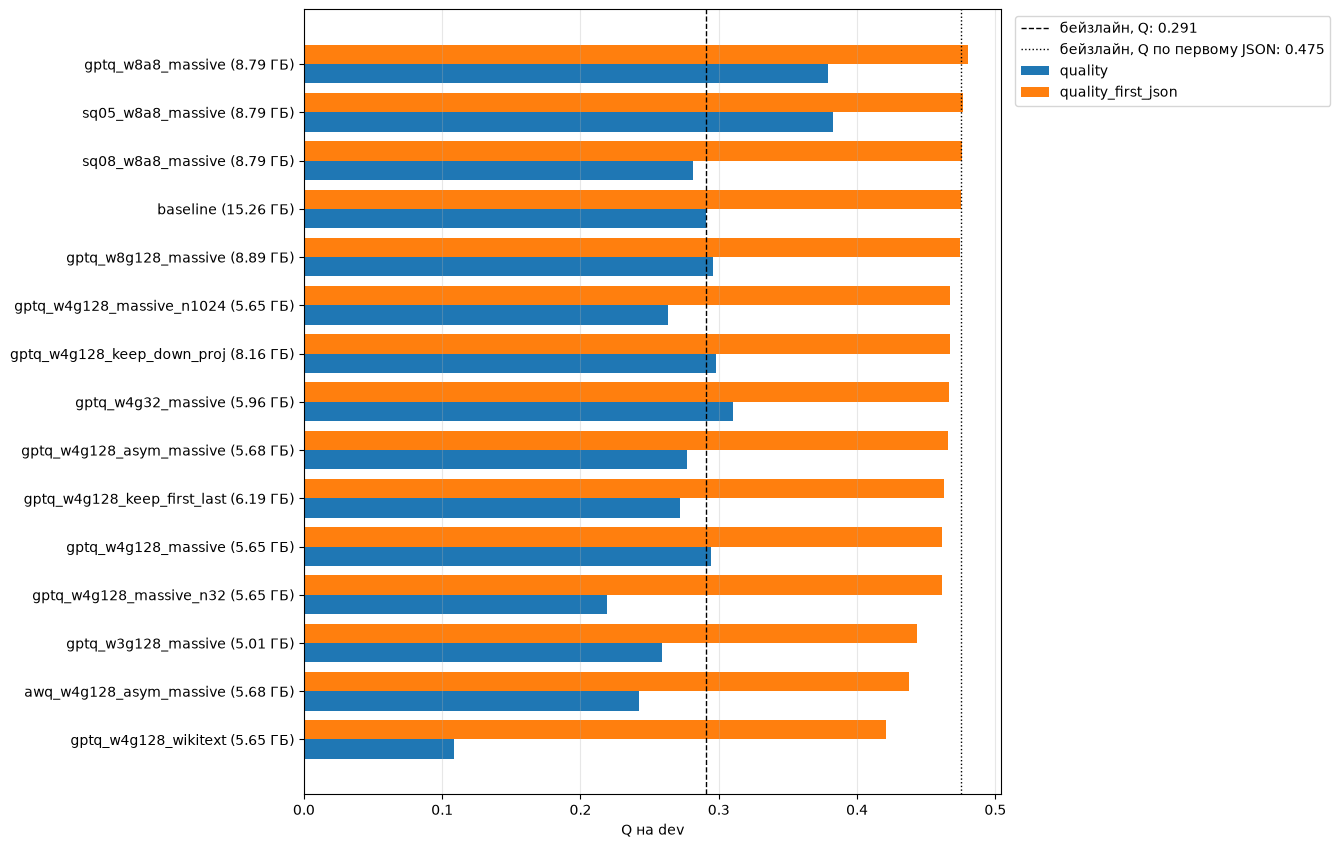

In [ ]:
quant_results = [run_quantization(cfg) for cfg in tqdm(QUANT_CONFIGS, desc="quantization")]

def cached_predictions(name: str) -> list[str]:
    lines = (EVAL_DIR / name / "predictions.jsonl").read_text(encoding="utf-8").splitlines()
    return [json.loads(line)["prediction"] for line in lines]

def first_json(text: str) -> str:
    try:
        return json.dumps(json.JSONDecoder().raw_decode(text.strip())[0], ensure_ascii=False)
    except ValueError:
        return text

def quality_first_json(name: str, ds: Dataset) -> float:
    return compute_metrics([first_json(p) for p in cached_predictions(name)], ds["gold"], INTENTS, SLOT_TYPES)["quality"]

def same_as_baseline(name: str) -> float:
    return float(np.mean([p == b for p, b in zip(cached_predictions(name), baseline_predictions)]))

for row in quant_results:
    row["quality_first_json"] = quality_first_json(row["run"], dev_data)
    row["same_as_bf16"] = same_as_baseline(row["run"])
results += quant_results
quant_table = pd.DataFrame([{**results[0], "bits": 16, "same_as_bf16": 1.0,
                             "quality_first_json": quality_first_json("baseline", dev_data),
                             "size_gb": round(checkpoint_size_gb(BASELINE_PATH), 2)}] + quant_results)
quant_table.to_csv(ARTIFACTS / "quantization_results.csv", index=False)
columns = ["run", "method", "bits", "group_size", "symmetric", "activations", "calibration", "samples",
           "smoothing", "kept_bf16", "size_gb", "quality", "intent_accuracy", "slot_micro_f1",
           "frame_exact_match", "valid_json_rate", "quality_first_json", "same_as_bf16"]
display(quant_table[columns].round(4))

import matplotlib.pyplot as plt

PLOTS = ARTIFACTS / "plots"
PLOTS.mkdir(exist_ok=True)

def plot_quality(table: pd.DataFrame, path: Path, lines: dict[str, float], columns: Sequence[str] = ("quality",)) -> None:
    table = table.sort_values(columns[-1])
    y, height = np.arange(len(table)), 0.8 / len(columns)
    fig, ax = plt.subplots(figsize=(9, 0.3 * len(table) * len(columns) + 1.2))
    for k, column in enumerate(columns):
        ax.barh(y + k * height, table[column], height=height, label=column)
    ax.set_yticks(y + height * (len(columns) - 1) / 2, table["label"])
    for (name, value), style in zip(lines.items(), ["--", ":", "-."]):
        ax.axvline(value, color="black", linestyle=style, linewidth=1, label=f"{name}: {value:.3f}")
    ax.set_xlabel("Q на dev")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()

plot_quality(quant_table.assign(label=[f"{r.run} ({r.size_gb} ГБ)" for r in quant_table.itertuples()]),
             PLOTS / "quantization.png",
             {"бейзлайн, Q": baseline_metrics["quality"], "бейзлайн, Q по первому JSON": quant_table["quality_first_json"][0]},
             columns=("quality", "quality_first_json"))

### Выводы

Все числа - на всём dev (2032 записи, шум Q около ±0.01). Кроме Q из задания в таблице есть `quality_first_json` - Q, если из ответа брать первый JSON-объект, - и `same_as_bf16` - доля ответов, совпавших с бейзлайном символ в символ.

**Почему одной Q мало.** 46.5% ответов бейзлайна невалидны, и почти все они - правильный JSON с лишней `}` в конце (41% всех ответов). Поэтому Q квантизованных моделей почти целиком определяется тем, где модель останавливается: корреляция Q и `valid_json_rate` по 15 запускам - 0.996. Шум квантизации может и ломать, и «чинить» остановку: W8A8 поднимает Q с 0.291 до 0.379, хотя совпадает с ответами bf16 только в 46% случаев. Значимость параметров оцениваю по `quality_first_json` (у бейзлайна 0.475) и совпадению с bf16.

**1. Калибровочный датасет** (GPTQ W4, group 128, 256 примеров). MASSIVE train: Q 0.294, по первому JSON 0.462, совпадение с bf16 61%. WikiText: Q 0.109, по первому JSON 0.421, совпадение 17%, валидного JSON 15.5%. GPTQ подбирает поправки весов под активации калибровочных данных; английские статьи без chat-шаблона и system prompt дают другое распределение, и модель теряет формат (в 28% ответов JSON вообще не разбирается) и хуже определяет intent (0.56 против 0.66 по первому JSON). Это самый сильный фактор из всех.

**2. Конфигурации**
- битность: W8 без потерь (GPTQ W8 g128 - 0.475, W8A8 - 0.480 по первому JSON), W4 теряет около 0.01 (0.461-0.467), W3 - 0.03 (0.443) и в 36% ответов ломает JSON;
- число калибровочных примеров: 32 - 0.461 и валидный JSON только у 39.5% ответов, 256 и 1024 - 0.462 и 0.467, разницы нет;
- group size 32 против 128: 0.466 против 0.462 - в пределах шума при +0.3 ГБ;
- symmetric против asymmetric: 0.462 против 0.465; асимметричная сетка ближе к bf16 (совпадение 65% против 61%, относительная ошибка весов `down_proj` 0.133 против 0.149);
- AWQ W4 asym: 0.438 - хуже GPTQ с той же схемой (0.465);
- SmoothQuant + W8A8 (int8 активации по токену): потерь нет уже без сглаживания (0.480), со smoothing_strength 0.5 и 0.8 - 0.476. Сглаживание приближает ответы к bf16 (совпадение 46% → 50% → 57%), то есть уменьшает ошибку квантизации активаций, но с динамической шкалой на каждый токен её и так мало;
- слои в bf16: все `down_proj` (+2.5 ГБ) - 0.467 и совпадение 64% против 61%, небольшой выигрыш; первый и последний блок (+0.5 ГБ) - 0.463, не помогает. На вход `down_proj` идут активации после SwiGLU с самыми большими выбросами, поэтому его ошибка квантизации больше; первый и последний блок здесь не узкое место.

**3. Что значимо.** По убыванию: калибровочные данные (-0.054 по первому JSON и развал формата), битность (W8 без потерь, W4 -0.01, W3 -0.03), метод (AWQ -0.037 против GPTQ -0.013) и слишком мало калибровочных примеров (32 - валидность падает до 40%). Group size, симметрия, smoothing_strength и оставленные в bf16 слои меняют качество в пределах шума. Лучший компромисс - GPTQ W4 g128 на MASSIVE: 5.65 ГБ вместо 15.26 и -0.013 по первому JSON; без потерь - W8 (8.9 ГБ).

## Hard-label дистилляция (5 баллов)

Теперь реализуем hard-label дистилляцию знаний от учителя **Qwen3-32B** в бейзлайн.

### Задания
1) Измерьте качество учителя на dev и сравните с бейзлайном: насколько учитель сильнее? (1 балл)
2) Получите жадные ответы учителя на сэмпле из train. Используйте батч для ускорения при необходимости (1 балл)
3) Реализуйте код для обучения ученика на ответах учителя (1 балл)
4) Проведите эксперименты с обучением, получите модель ученика, отклоняющуюся на dev не более чем на 10% от метрики учителя (2 балла)


### Измерим качество учителя и сравним с бейзлайном (1 балл)

In [16]:
STUDENT_MODEL_ID = BASE_MODEL_ID
TEACHER_MODEL_ID = "Qwen/Qwen3-32B"
TEACHER_ANSWERS_PATH = ARTIFACTS / "teacher_answers"

teacher_tokenizer = AutoTokenizer.from_pretrained(TEACHER_MODEL_ID)
if (
    tokenizer.get_vocab() != teacher_tokenizer.get_vocab()
    or tokenizer.chat_template != teacher_tokenizer.chat_template
    or tokenizer.eos_token_id != teacher_tokenizer.eos_token_id
    or tokenizer.pad_token_id != teacher_tokenizer.pad_token_id
):
    raise ValueError("Токенизаторы ученика и учителя различаются.")
del teacher_tokenizer

In [ ]:
teacher = None
if not (EVAL_DIR / "teacher" / "metrics.json").exists() or not (TEACHER_ANSWERS_PATH / "answers.jsonl").exists():
    teacher = AutoModelForCausalLM.from_pretrained(
        TEACHER_MODEL_ID, torch_dtype=torch.bfloat16,
        device_map=DEVICE,
    ).eval()
student_vocab_size = AutoConfig.from_pretrained(STUDENT_MODEL_ID).vocab_size
if AutoConfig.from_pretrained(TEACHER_MODEL_ID).vocab_size != student_vocab_size:
    raise ValueError("Размерности выходных логитов teacher и student различаются.")

In [18]:
teacher_metrics, teacher_predictions = evaluate_cached("teacher", TEACHER_MODEL_ID, dev_data, model=teacher)
(ARTIFACTS / "teacher_dev.json").write_text(json.dumps(teacher_metrics, indent=2), encoding="utf-8")
results.append({"run": "teacher", "path": TEACHER_MODEL_ID, "method": "dense", "calibration": None, **teacher_metrics})

comparison = pd.DataFrame(
    [baseline_metrics, teacher_metrics], index=["baseline Qwen3-8B", "teacher Qwen3-32B"]
).drop(columns="n")
comparison.loc["teacher - baseline"] = comparison.iloc[1] - comparison.iloc[0]
comparison.loc["teacher / baseline"] = comparison.iloc[1] / comparison.iloc[0]
display(comparison.round(4))

def answer_errors(predictions: list[str]) -> pd.Series:
    """Доли ответов: невалидный JSON, неверный intent, верный intent с ошибкой в slots, полностью верный."""
    kinds = []
    for pred_text, gold_text in zip(predictions, dev_data["gold"]):
        pred, gold = parse_answer(pred_text, INTENTS, SLOT_TYPES), json.loads(gold_text)
        if pred is None:
            kinds.append("invalid")
        elif pred["intent"] != gold["intent"]:
            kinds.append("wrong intent")
        elif slot_counter(pred) != slot_counter(gold):
            kinds.append("wrong slots")
        else:
            kinds.append("exact")
    return pd.Series(kinds).value_counts(normalize=True)

display(pd.DataFrame({"baseline": answer_errors(baseline_predictions),
                      "teacher": answer_errors(teacher_predictions)}).fillna(0).round(3))

,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate
baseline Qwen3-8B,0.2909,0.3716,0.2103,0.0989,0.5349
teacher Qwen3-32B,0.5621,0.7515,0.3727,0.2844,0.9734
teacher - baseline,0.2712,0.3799,0.1625,0.1855,0.4385
teacher / baseline,1.9322,2.0225,1.7726,2.8756,1.8197


,baseline,teacher
exact,0.099,0.284
invalid,0.465,0.027
wrong intent,0.163,0.222
wrong slots,0.273,0.467


### Получим ответы учителя на трейне (1 балл)

Не забывайте выгружать модели и очищать память.

In [ ]:
DISTILL_SAMPLES = None
TEACHER_BATCH_SIZE = 64

def collect_teacher_answers(
    model: PreTrainedModel,
    tokenizer: PreTrainedTokenizerBase,
    rows: Dataset,
    output_path: str | Path,
) -> Path:
    """Генерируем ответы учителя батчами и сохраняем их в answers.jsonl.

    Args:
        model: модель-учитель.
        tokenizer: общий токенизатор учителя и ученика.
        rows: примеры train с полями `id`, `text`, `gold`.
        output_path: пустой каталог для ответов.

    Returns:
        Каталог с answers.jsonl; в каждой строке `id`, `text`, `gold`,
        `teacher_answer`, `prompt_ids`, `answer_ids`.
    """
    output_path = ensure_empty_dir(output_path)
    records = []
    row_list = list(rows)

    prompts = [encode_prompt(tokenizer, row["text"]) for row in row_list]
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    answers = [None] * len(prompts)
    for start in tqdm(range(0, len(order), TEACHER_BATCH_SIZE), desc="teacher answers"):
        batch = order[start:start + TEACHER_BATCH_SIZE]
        for i, ids in zip(batch, generate_answer_ids(model, tokenizer, [prompts[i] for i in batch])):
            answers[i] = ids
    for row, prompt_ids, answer_ids in zip(row_list, prompts, answers):
        if not answer_ids or answer_ids[-1] != tokenizer.eos_token_id:
            continue
        records.append({
            "id": row["id"], "text": row["text"], "gold": row["gold"],
            "teacher_answer": tokenizer.decode(answer_ids, skip_special_tokens=True),
            "prompt_ids": prompt_ids, "answer_ids": answer_ids,
        })

    if not records:
        raise ValueError("Учитель не вернул ни одного ответа.")
    (output_path / "answers.jsonl").write_text(
        "".join(json.dumps(row, ensure_ascii=False) + "\n" for row in records),
        encoding="utf-8",
    )
    print(f"Сохранено ответов: {len(records)} / {len(row_list)}")
    return output_path

In [20]:
distill_rows = train_data.shuffle(seed=SEED)
if DISTILL_SAMPLES is not None:
    distill_rows = distill_rows.select(range(min(DISTILL_SAMPLES, len(train_data))))
if not (TEACHER_ANSWERS_PATH / "answers.jsonl").exists():
    collect_teacher_answers(teacher, tokenizer, distill_rows, TEACHER_ANSWERS_PATH)
TEACHER_ANSWERS = TEACHER_ANSWERS_PATH
del teacher
clean_memory()

teacher_train = [json.loads(line) for line in (TEACHER_ANSWERS / "answers.jsonl").read_text(encoding="utf-8").splitlines()]
teacher_train_metrics = compute_metrics(
    [r["teacher_answer"] for r in teacher_train], [r["gold"] for r in teacher_train], INTENTS, SLOT_TYPES
)
print(f"Ответов учителя: {len(teacher_train)} из {len(distill_rows)}")
print("Качество ответов учителя на train относительно gold:", {k: round(v, 4) for k, v in teacher_train_metrics.items()})

Ответов учителя: 11512 из 11514
Качество ответов учителя на train относительно gold: {'quality': 0.5624, 'intent_accuracy': 0.7503, 'slot_micro_f1': 0.3744, 'frame_exact_match': 0.2748, 'valid_json_rate': 0.9745, 'n': 11512}


### Реализация пайплайна обучения ученика (1 балл)

Полное дообучение Qwen3-8B на A100 80GB проходит на грани по памяти. Для решения можно включать gradient checkpointing, уменьшать batch или брать меньшую модель того же семейства.

In [21]:
class TeacherAnswerDataset(torch.utils.data.Dataset):
    """Примеры для обучения ученика на ответах учителя."""

    def __init__(self, path: str | Path, limit: int | None = None, only_valid: bool = True) -> None:
        """

        Args:
            path: каталог с answers.jsonl из collect_teacher_answers.
            limit: сколько первых примеров взять (train перемешан с SEED); None - все.
            only_valid: отбросить ответы учителя, не прошедшие parse_answer.
        """
        self.rows = [] # Список примеров из файла

        lines = (Path(path) / "answers.jsonl").read_text(encoding="utf-8").splitlines()
        rows = [json.loads(line) for line in lines]
        if only_valid:
            rows = [r for r in rows if parse_answer(r["teacher_answer"], INTENTS, SLOT_TYPES) is not None]
        self.rows = rows[:limit]

    def __len__(self) -> int:
        """
            Число строк в answers.jsonl.
        """
        return len(self.rows)

    def __getitem__(self, index: int) -> dict[str, list[int]]:
        """
        Args:
            index: номер примера.

        Returns:
            Словарь с `input_ids` (промпт + ответ), `attention_mask` и `labels`,
            токены промпта маскируем значением -100.
        """
        row = self.rows[index]
        input_ids = row["prompt_ids"] + row["answer_ids"]
        labels = [-100] * len(row["prompt_ids"]) + row["answer_ids"]
        return {
            "input_ids": input_ids,
            "attention_mask": [1] * len(input_ids),
            "labels": labels,
        }

def collate_teacher_answers(features: list[dict[str, list[int]]]) -> dict[str, torch.Tensor]:
    """Паддим примеры справа до общей длины батча.

    Args:
        features: примеры из TeacherAnswerDataset.

    Returns:
        Тензоры `input_ids`, `attention_mask` и `labels` формы [batch, length];
        паддинг в `labels` равен -100.
    """
    pad_id = tokenizer.pad_token_id
    if pad_id is None:
        pad_id = tokenizer.eos_token_id
    width = max(len(feature["input_ids"]) for feature in features)
    batch = {"input_ids": [], "attention_mask": [], "labels": []}
    for feature in features:
        pad = width - len(feature["input_ids"])
        batch["input_ids"].append(feature["input_ids"] + [pad_id] * pad)
        batch["attention_mask"].append(feature["attention_mask"] + [0] * pad)
        batch["labels"].append(feature["labels"] + [-100] * pad)
    return {key: torch.tensor(value) for key, value in batch.items()}

In [ ]:
STUDENTS_DIR = ARTIFACTS / "students"
MICRO_BATCH = 4

@dataclass(frozen=True)
class DistillConfig:
    """Одна конфигурация обучения ученика.

    Attributes:
        name: имя эксперимента и каталога students/<name>.
        samples: сколько ответов учителя взять; None - все.
        learning_rate: пиковый learning rate (cosine, warmup 5%).
        epochs: число эпох.
        batch_size: эффективный батч (MICRO_BATCH x gradient accumulation).
        only_valid: учить только на валидных ответах учителя.
        fp32_master: держать веса и состояния AdamW в fp32, считать в bf16 autocast.
            Иначе веса в bf16: обновления порядка lr*1 теряются при округлении весов.
        freeze_embeddings: не обучать embed_tokens и lm_head.
        student_model_id: модель ученика.
    """
    name: str
    samples: int | None = 2048
    learning_rate: float = 1e-5
    epochs: float = 2
    batch_size: int = 16
    only_valid: bool = True
    fp32_master: bool = True
    freeze_embeddings: bool = True
    student_model_id: str = STUDENT_MODEL_ID

def train_student(cfg: DistillConfig) -> Path:
    """Обучает ученика на ответах учителя и сохраняет его в bf16 в students/<name>.

    Если модель уже обучена и сохранена, возвращает её путь.
    """
    path = STUDENTS_DIR / cfg.name
    if (path / "config.json").exists():
        return path
    set_seed(SEED)
    student = AutoModelForCausalLM.from_pretrained(
        cfg.student_model_id, torch_dtype=torch.float32 if cfg.fp32_master else torch.bfloat16,
    )
    student.config.use_cache = False
    if cfg.freeze_embeddings:
        student.get_input_embeddings().requires_grad_(False)
        student.get_output_embeddings().requires_grad_(False)
    train_set = TeacherAnswerDataset(TEACHER_ANSWERS_PATH, limit=cfg.samples, only_valid=cfg.only_valid)
    args = TrainingArguments(
        output_dir=str(ARTIFACTS / "trainer" / cfg.name),
        per_device_train_batch_size=MICRO_BATCH,
        gradient_accumulation_steps=cfg.batch_size // MICRO_BATCH,
        learning_rate=cfg.learning_rate, num_train_epochs=cfg.epochs,
        lr_scheduler_type="cosine", warmup_ratio=0.05, weight_decay=0.0,
        bf16=True, gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        optim="adamw_torch_fused", logging_steps=10, save_strategy="no", report_to="none",
        remove_unused_columns=False, dataloader_num_workers=2, seed=SEED,
    )
    sft = Trainer(model=student, args=args, train_dataset=train_set, data_collator=collate_teacher_answers)
    train_output = sft.train()
    ensure_empty_dir(path)
    student.config.use_cache = True
    student.to(torch.bfloat16).save_pretrained(path, safe_serialization=True)
    tokenizer.save_pretrained(path)
    (path / "distill_config.json").write_text(json.dumps(asdict(cfg), indent=2), encoding="utf-8")
    (path / "train_log.json").write_text(json.dumps({
        "train_examples": len(train_set), "metrics": train_output.metrics, "log_history": sft.state.log_history,
    }, indent=2), encoding="utf-8")
    del sft, student
    clean_memory()
    return path

def run_distillation(cfg: DistillConfig) -> dict[str, Any]:
    """Обучает ученика, оценивает его на dev и возвращает строку таблицы результатов."""
    path = train_student(cfg)
    metrics, _ = evaluate_cached(f"student_{cfg.name}", path, dev_data)
    log = json.loads((path / "train_log.json").read_text(encoding="utf-8"))
    return {
        "run": cfg.name, "student": cfg.student_model_id, "samples": log["train_examples"],
        "lr": cfg.learning_rate, "epochs": cfg.epochs, "batch": cfg.batch_size,
        "only_valid": cfg.only_valid, "master_weights": "fp32" if cfg.fp32_master else "bf16",
        "train_loss": round(log["metrics"]["train_loss"], 4),
        "train_min": round(log["metrics"]["train_runtime"] / 60, 1),
        **metrics, "share_of_teacher": metrics["quality"] / teacher_metrics["quality"],
    }

MAIN_DISTILL = DistillConfig("n2048_lr1e-5_e2")
DISTILL_CONFIGS = [
    MAIN_DISTILL,
    DistillConfig("n128_lr1e-5_e2", samples=128),
    DistillConfig("n512_lr1e-5_e2", samples=512),
    DistillConfig("nall_lr1e-5_e1", samples=None, epochs=1),
    DistillConfig("n2048_lr3e-6_e2", learning_rate=3e-6),
    DistillConfig("n2048_lr3e-5_e2", learning_rate=3e-5),
    DistillConfig("n2048_lr1e-5_e2_with_invalid", only_valid=False),
    DistillConfig("n2048_lr1e-5_e2_bf16_master", fp32_master=False),
    DistillConfig("qwen3_4b_n2048_lr1e-5_e2", student_model_id="Qwen/Qwen3-4B"),
]

In [23]:
main_row = run_distillation(MAIN_DISTILL)
sft_metrics = {k: main_row[k] for k in baseline_metrics}
print(MAIN_DISTILL)
print({k: round(v, 4) for k, v in sft_metrics.items()})
print(f"Доля от качества учителя: {main_row['share_of_teacher']:.3f}")

DistillConfig(name='n2048_lr1e-5_e2', samples=2048, learning_rate=1e-05, epochs=2, batch_size=16, only_valid=True, fp32_master=True, freeze_embeddings=True, student_model_id='Qwen/Qwen3-8B')
{'quality': 0.5859, 'intent_accuracy': 0.7717, 'slot_micro_f1': 0.4002, 'frame_exact_match': 0.3056, 'valid_json_rate': 0.9946, 'n': 2032}
Доля от качества учителя: 1.042


### Добейтесь максимального качества ученика. Цель — не более 10% отклонения от учителя (2 балла)
Пробуйте менять гиперпараметры, число сэмплов, модели ученика (при условии размера модели ученика не более 8B).


distillation:   0%|          | 0/9 [00:00<?, ?it/s]


distillation: 100%|██████████| 9/9 [00:00<00:00, 118.69it/s]

,run,student,samples,lr,epochs,batch,only_valid,master_weights,train_loss,train_min,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate,share_of_teacher
0,n2048_lr1e-5_e2,Qwen/Qwen3-8B,2048,0.0,2,16,True,fp32,0.1416,7.3,0.5859,0.7717,0.4002,0.3056,0.9946,1.0424
1,n128_lr1e-5_e2,Qwen/Qwen3-8B,128,0.0,2,16,True,fp32,0.2657,0.5,0.5195,0.6890,0.3501,0.2308,0.9429,0.9243
2,n512_lr1e-5_e2,Qwen/Qwen3-8B,512,0.0,2,16,True,fp32,0.1773,1.8,0.5716,0.7451,0.3981,0.2849,0.9862,1.0169
3,nall_lr1e-5_e1,Qwen/Qwen3-8B,11219,0.0,1,16,True,fp32,0.1489,20.0,0.5919,0.7815,0.4024,0.2997,0.9995,1.0531
4,n2048_lr3e-6_e2,Qwen/Qwen3-8B,2048,0.0,2,16,True,fp32,0.1298,7.3,0.5905,0.7790,0.4020,0.3056,0.9966,1.0506
5,n2048_lr3e-5_e2,Qwen/Qwen3-8B,2048,0.0,2,16,True,fp32,0.1927,7.2,0.5782,0.7721,0.3842,0.2977,0.9961,1.0286
6,n2048_lr1e-5_e2_with_invalid,Qwen/Qwen3-8B,2048,0.0,2,16,False,fp32,0.1477,7.3,0.5845,0.7677,0.4012,0.3081,0.9823,1.0398
7,n2048_lr1e-5_e2_bf16_master,Qwen/Qwen3-8B,2048,0.0,2,16,True,bf16,0.1459,5.9,0.5797,0.7687,0.3907,0.2933,0.9931,1.0313
8,qwen3_4b_n2048_lr1e-5_e2,Qwen/Qwen3-4B,2048,0.0,2,16,True,fp32,0.1609,5.1,0.5814,0.7628,0.4001,0.3081,0.9921,1.0344


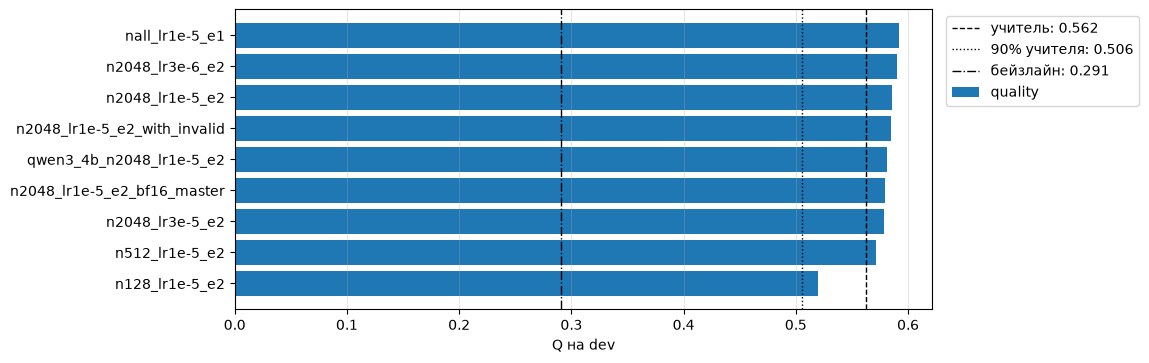

,split,model,quality,intent_accuracy,slot_micro_f1,frame_exact_match,valid_json_rate,quality_first_json,share_of_teacher
0,dev,baseline,0.2909,0.3716,0.2103,0.0989,0.5349,0.4751,0.5175
1,dev,teacher,0.5621,0.7515,0.3727,0.2844,0.9734,0.5621,1.0000
2,dev,student_sft,0.5919,0.7815,0.4024,0.2997,0.9995,0.5919,1.0531
3,test,baseline,0.2646,0.3463,0.1828,0.1029,0.5155,0.4485,0.4840
4,test,teacher,0.5466,0.7397,0.3534,0.2619,0.9765,0.5467,1.0000
5,test,student_sft,0.5832,0.7781,0.3883,0.2777,0.9997,0.5832,1.0670


In [ ]:
distill_results = [run_distillation(cfg) for cfg in tqdm(DISTILL_CONFIGS, desc="distillation")]
distill_table = pd.DataFrame(distill_results)
distill_table.to_csv(ARTIFACTS / "distillation_results.csv", index=False)
display(distill_table.drop(columns=["n"]).round(4))
plot_quality(distill_table.assign(label=distill_table["run"]), PLOTS / "distillation.png", {
    "учитель": teacher_metrics["quality"], "90% учителя": 0.9 * teacher_metrics["quality"],
    "бейзлайн": baseline_metrics["quality"],
})

best = max(distill_results, key=lambda row: row["quality"])
STUDENT_PATH = ARTIFACTS / "student_sft"
if not (STUDENT_PATH / "config.json").exists():
    shutil.copytree(STUDENTS_DIR / best["run"], STUDENT_PATH, dirs_exist_ok=True)
student_metrics, student_predictions = evaluate_cached("student_sft", STUDENT_PATH, dev_data)
(ARTIFACTS / "student_dev.json").write_text(json.dumps(
    {"config": best["run"], **student_metrics, "share_of_teacher": student_metrics["quality"] / teacher_metrics["quality"]},
    indent=2), encoding="utf-8")
results.append({"run": "student_sft", "path": str(STUDENT_PATH), "method": "distill", "calibration": None, **student_metrics})

test_data = data["test"]
final_rows = []
for split, ds in (("dev", dev_data), ("test", test_data)):
    split_metrics = {}
    for name, model_path in (("baseline", BASELINE_PATH), ("teacher", TEACHER_MODEL_ID), ("student_sft", STUDENT_PATH)):
        eval_name = name if split == "dev" else f"{name}_test"
        split_metrics[name] = {**evaluate_cached(eval_name, model_path, ds)[0],
                               "quality_first_json": quality_first_json(eval_name, ds)}
    for name, m in split_metrics.items():
        final_rows.append({"split": split, "model": name, **m,
                           "share_of_teacher": m["quality"] / split_metrics["teacher"]["quality"]})
final = pd.DataFrame(final_rows).drop(columns="n")
final.to_csv(ARTIFACTS / "final_comparison.csv", index=False)
display(final.round(4))
pd.DataFrame(results).to_csv(ARTIFACTS / "all_results.csv", index=False)

### Выводы

**1. Учитель против бейзлайна.** Qwen3-32B: Q 0.562 против 0.291 (в 1.93 раза), intent accuracy 0.751 против 0.372, slot F1 0.373 против 0.210, валидного JSON 97.3% против 53.5%. Большая часть разрыва - формат: по первому JSON-объекту бейзлайн набирает 0.475, то есть учитель сильнее и по формату, и по сути (+0.09). Слабое место обоих - slots: в 47% всех ответов учителя intent верный, а slots нет (другой тип, например `device_type` вместо `house_place`, лишние или склеенные slots, значение в начальной форме вместо формы из запроса).

**2. Ответы учителя.** Жадные ответы на весь train (11 514 запросов, батч 64, около 20 минут на H200): 11 512 закончились eos, 2 обрезаны лимитом 128 токенов и отброшены. 2.6% ответов - невалидный JSON, в обучение по умолчанию они не идут. Относительно gold ответы учителя на train дают Q 0.562, как на dev: ученик учится на шумных метках, полностью верный фрейм только у 27.5% из них.

**3. Обучение.** Полное дообучение Qwen3-8B: все 36 блоков, эмбеддинги и lm_head заморожены, чтобы fp32-копия весов с градиентами и AdamW поместилась в 140 ГБ H200. Loss только на токенах ответа, bf16 autocast, gradient checkpointing, батч 16, cosine, warmup 5%.

**4. Эксперименты** (Q на dev, учитель 0.562, порог 90% - 0.506)
- число ответов учителя: 128 - 0.520 (92% учителя, цель достигнута уже здесь), 512 - 0.572, 2048 - 0.586, весь train (11 219 валидных ответов, 1 эпоха) - 0.592. Основной прирост - до 512 примеров: ученику нужно выучить формат ответа и то, как учитель размечает slots;
- learning rate (2048 примеров, 2 эпохи): 3e-6 - 0.591, 1e-5 - 0.586, 3e-5 - 0.578; при 3e-5 выше и train loss (0.193 против 0.130);
- невалидные ответы учителя в обучении: 0.584 и валидный JSON у 98.2% ответов против 99.5% - ученик перенимает и ошибки формата;
- веса в bf16 вместо fp32: 0.580 против 0.586, в пределах шума. Обновления меньше шага сетки bf16 теряются, но для этой задачи (в основном формат) оставшихся хватает;
- ученик Qwen3-4B: 0.581 - вдвое меньшая модель почти не уступает 8B.

**5. Итог.** Лучший ученик `nall_lr1e-5_e1` сохранён в `student_sft`: Q 0.592 на dev (105% учителя, вдвое выше бейзлайна) и 0.583 на test (107% учителя), отклонение от учителя положительное. Учителя он обходит за счёт формата: обучен только на валидных ответах и всегда выдаёт валидный JSON (100% против 97.3%). Его intent accuracy 0.781 близка к точности учителя на его валидных ответах (0.751 / 0.973 = 0.772). Ученик выбран по dev, но на test отрыв от учителя тот же, так что это не подгонка под dev.